# Tikhonov regularization, the conjugate gradient method and the L-curve
Consider the problem from lab 3. Another approach that can avoid the effects of semi-convergence is to solve instead of the least-squares problem
$$ \min_{\alpha} \frac{1}{2} \| A \alpha - g \|^2 $$
the regularized problem
$$ \min_{\alpha} \frac{1}{2} \| A \alpha - g \|^2 + \frac{\lambda}{2} \| \alpha \|^2 $$
with a regularization parameter $\lambda > 0$. It turns out that for a suitably chosen parameter $\lambda$ (depending on the noise level and the problem) the exact solution of the regularized problem (called [Tikhonov regularization](https://en.wikipedia.org/wiki/Tikhonov_regularization)) is a more accurate reconstruction than a solution of the unregularized problem (though there are typically better regularization alternatives). The optimality condition now reads $0 = A^t (A \alpha - g) + \lambda \alpha$. For the reconstruction problem described in lab 3, find a regularized solution for some choice of $\lambda$ using the conjugate gradient method and plot the relative error. Then, try to find a good choice of the parameter $\lambda$ with the L-curve method. For the L-curve you should not do a full reconstruction for each $\lambda$, but only a few iterations to save time. Compare with the Landweber solution. 

Make sure to keep $\lambda$ in a reasonable range, otherwise ``odl.solvers.conjugate_gradient`` divides by zero once the residual underflows. This problem typically kicks in with very large regularization parameters, in this case $\lambda \sim 10^3$.

Calculating L-curve (this will take a moment)...


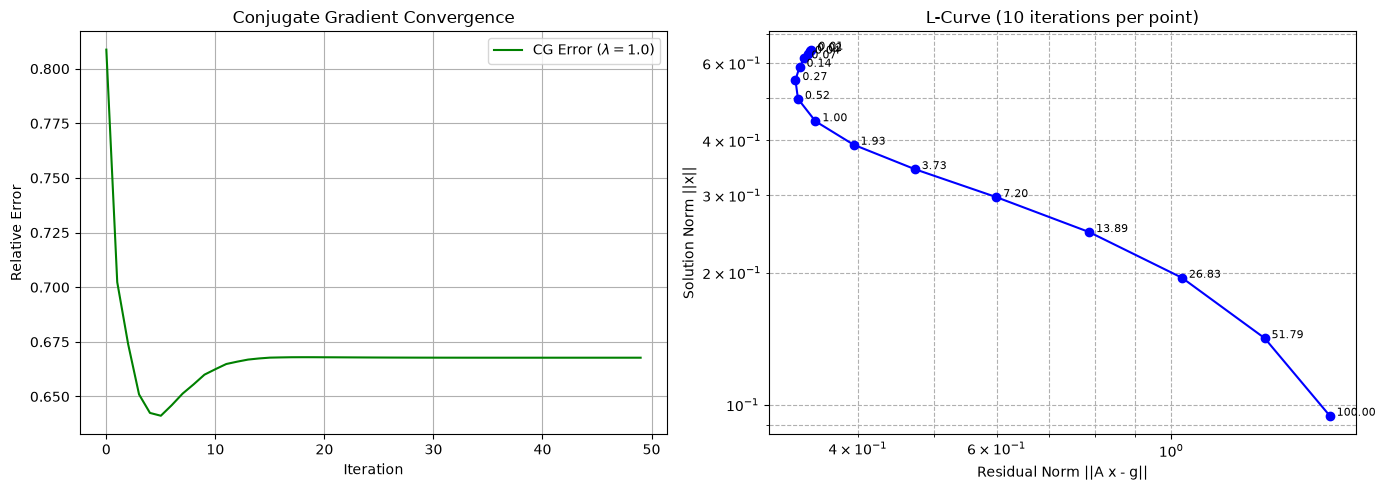

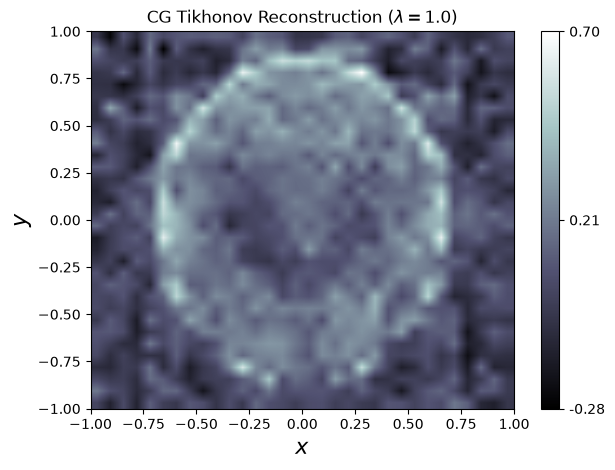

<Figure size 640x480 with 0 Axes>

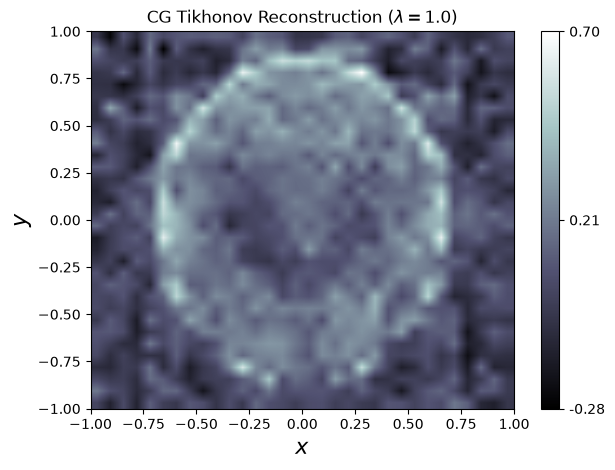

In [1]:
import odl
import odl.applications.tomo
import numpy as np
import matplotlib.pyplot as plt

# --- 1. Setup (Same as Lab 3) ---
space = odl.uniform_discr([-1, -1, -1], [1, 1, 1], shape=(32, 32, 32), dtype='float32')
phantom = odl.phantom.shepp_logan(space, modified=True)
geometry = odl.applications.tomo.cone_beam_geometry(space, src_radius=3, det_radius=3, num_angles=10)
operator = odl.applications.tomo.RayTransform(space, geometry)

# Generate noisy sinogram
g_exact = operator(phantom)
noise = odl.phantom.noise.white_noise(operator.range)
noise_level = 0.05 * odl.max(odl.abs(g_exact))
g_noisy = g_exact + float(noise_level) * noise

# Right hand side for the normal equations: A* g
rhs = operator.adjoint(g_noisy)

# Identity operator for the lambda * I term
I = odl.IdentityOperator(space)

# --- 2. Single Tikhonov Reconstruction with CG ---
lambda_val = 1.0  # Initial guess for lambda
op_cg = operator.adjoint * operator + float(lambda_val) * I

x_cg = space.zero()
rel_errors_cg = []

# Callback to track the relative error during CG iterations
def callback_cg(x):
    rel_errors_cg.append((x - phantom).norm() / phantom.norm())

# Run CG. It converges much faster than Landweber, so 50 iterations are plenty.
odl.solvers.conjugate_gradient(op_cg, x_cg, rhs, niter=50, callback=callback_cg)

# --- 3. L-Curve Method ---
# We test a range of lambda values from 0.01 to 100 to avoid the 10^3 divide-by-zero bug
lambdas = np.logspace(-2, 2, 15)  
residual_norms = []
solution_norms = []

print("Calculating L-curve (this will take a moment)...")
for lam in lambdas:
    op_lam = operator.adjoint * operator + float(lam) * I
    x_lam = space.zero()
    
    # Only 10 iterations per lambda to save time
    odl.solvers.conjugate_gradient(op_lam, x_lam, rhs, niter=10)
    
    # L-curve metrics: ||A x_lam - g_noisy|| and ||x_lam||
    res_norm = (operator(x_lam) - g_noisy).norm()
    sol_norm = x_lam.norm()
    
    residual_norms.append(res_norm)
    solution_norms.append(sol_norm)

# --- 4. Plotting ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Relative Error of the single CG run
axes[0].plot(rel_errors_cg, color='green', label=fr'CG Error ($\lambda={lambda_val}$)')
axes[0].set_xlabel('Iteration')
axes[0].set_ylabel('Relative Error')
axes[0].set_title('Conjugate Gradient Convergence')
axes[0].grid(True)
axes[0].legend()

# Plot 2: L-Curve
axes[1].loglog(residual_norms, solution_norms, 'bo-')
axes[1].set_xlabel('Residual Norm ||A x - g||')
axes[1].set_ylabel('Solution Norm ||x||')
axes[1].set_title('L-Curve (10 iterations per point)')
axes[1].grid(True, which="both", ls="--")

# Annotate lambda values directly on the L-curve
for i, lam in enumerate(lambdas):
    axes[1].annotate(f"{lam:.2f}", (residual_norms[i], solution_norms[i]), 
                     fontsize=8, xytext=(5, 0), textcoords='offset points')

plt.tight_layout()
plt.show()

# Show the CG reconstruction for the initial lambda
x_cg.show(title=fr"CG Tikhonov Reconstruction ($\lambda={lambda_val}$)", force_show=True)